# 11 - Pilot: router + flag-gated text conditioning

3 conflict rows of one test photo (object, colour, material) x 6 arms, identical seed / 512 px / 20 steps. Nothing is trained.

| arm | what it is |
|---|---|
| `A_fixed` | `Pipeline.run(shaped=False)`, fixed guidance baseline |
| `B0_scheduled` | control: schedule with centre values (separates router from schedule) |
| `B_router` | existing learned router (`models/router.pt`) |
| `D_flaggate` | A + flag-gated text (colour / material words blended toward the neutral caption by the governance flag) |
| `D_hard` | control: D with both flags forced to 1 (enforcement without the detector) |
| `E_router_flaggate` | B + flag-gated text |

**Run the cells in order.** Runs all 3 rows x 6 arms = 18 images (~8 s each). Set `SMOKE = True` in the run cell for a colour-row-only check.
Needs Drive: `pilot_v1.zip`, and `governance/governance.pt` (if missing, rule labels are used and the run says so).
Send back: the printed table, `contact_sheet.png`, `config.json`, `scores.csv`, `timings.json` (copied to Drive by the last cell).

In [1]:
%%bash
pip uninstall -y torchao -q
pip install -q -U diffusers transformers accelerate safetensors peft lpips opencv-python-headless
nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [3]:
import os, sys, glob, json, zipfile, base64, zlib, subprocess
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
from google.colab import drive
drive.mount("/content/drive")
DRIVE_ROOT = "/content/drive/MyDrive/sketchy_dataset_one_sketch"
GOV = f"{DRIVE_ROOT}/governance/governance.pt"
REPO = "/content/repo"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "-q", "-b", "governed-pipeline", "https://github.com/Harshitha-282007/IE643_final.git", REPO], check=True)
p = f"{REPO}/src/pipeline.py"
src = open(p).read()
if "text_flags" not in src:
    MIX = '''    @staticmethod
    def mix_text(pr, pooled, tn, pn, flags):
        """Flag-gated text conditioning: each attribute's neutral caption is blended in with weight = its flag."""
        for w, f in (("colour", float(flags[0])), ("material", float(flags[1]))):
            if tn.get(w) is not None and f:
                pr = pr - f * (pr - tn[w].to(pr.dtype))
                pooled = pooled - f * (pooled - pn[w].to(pooled.dtype))
        return pr, pooled

'''
    RUNBLK = '''        if text_flags is not None:
            nz = it.get("txt_neutral") or {}
            tn = {w: None if v is None else torch.cat([npe, v[0].to(dev)]) for w, v in nz.items()}
            pn = {w: None if v is None else torch.cat([nppe, v[1].to(dev)]) for w, v in nz.items()}
            pr, pooled = self.mix_text(pr, pooled, tn, pn, text_flags)
'''
    a = "    @torch.no_grad()\n    def run_role("
    b = "    def run(self, it, p=None, shaped=True, gates=None, split=True, style_only=None, guided=False, seed_off=0):"
    c = "        governed = gates is not None\n"
    assert src.count(a) == 1 and src.count(b) == 1 and src.count(c) == 1
    src = src.replace(a, MIX + a).replace(b, b[:-2] + ", text_flags=None):").replace(c, RUNBLK + c)
    open(p, "w").write(src)
open(f"{REPO}/src/pilot_flag_gate.py", "wb").write(zlib.decompress(base64.b64decode("eNqdWW2P47YR/u5fQagIVkp0uvWlbYJNheKu94Kgl+thE/SLsRBoi7Z5liWVpHfXue5/7zNDSpa83pd0cbElcjhvnHlmxomiaPJZV427EGWjrFhWcvViJZ0qhVO3TiyautRON7WuV2LbXCusVM3OiJdiCyqjZZUKWZf+tKYD27axStxotxZurYS61dbRadPscODvk8m/agXm1ol23bgmBZVRxLdeVnrhQHdjRdzMv6iFS4O4tJeWpGJJ8qXZ2lToUtVOL2QlrILKL4VRtql2pDBerFOtvZhMBP5eF0t9C5Lh32fdqkrXKjO7OrZr2aoyfy8rqxLx+J9ntdrpUtYLJebSMh8R/+Pdp9/eXSYs8c15YRdrVe6qg9hTEn8zuycFknecaaoL0bH0Dl7AfKPEtax2ynqphffzg3a2eSBopZHkw0fU6O+uUtLUMOO1c0bPcVxcggntfJR7ZVjy24KCh2LnGR5OObz4hM3jZYFrxsUWuOWElXgtvrsXi7GFQFi+WMt6BaOteJ0EyWtpxlf7XMnTVEyT5KSnmQLBZhakQCOmLOtd8O/Q2Gf7dyibhL45ZWU4TknF/F2zUkgkk0wm71klpJgSS9NsOb9WSEpTcxzWyt00ZiPibVOqygokwVujr1Xyk9BLSk5txa6W11JXcg5H0nFDsYRXopcIpZ2FIiTbb9Y4M+FtiuKzxsgF6NmAs0x8atyaggB8nZHwQJmJn7dypWB2q8wLTc/C6S2IsLRViJ6F7dlTyusVi70x2jlVQ70StsMDRanNTxMF2/YisFlL5yPSkkC70S38Cv82QiLvSVdk/26rDgKsAiDJWswJhsC+hIKTCJCnAVLGiS+2qbvnxnZP0FdNupd6t233QlpRt91SC/ZYwL+2nPA9fP75owibbH5/WiEzETCVYvJ3l558cGWBrrsAKz4ek2RLJd3OELp6WokcLNq1Aeh4WuJPkZK5ZqPqnq5WO1xKVSxkS3g4mby+/OVXkYtZFLAwSkU0BCl+D+FNz4eE9m+UZPR0LwWiq8k/f/70lpjHEYCbiJDQ9IWEjhC4k1ItRasXm4IxPybELAjokRGktP5dAeNtW2mXR1QbcJYQPZ8mF5x2uLT32qBmHAoH8ABmIip1mXg0HNcMjoKubAAi8VUjdG7WVJ6Owx6pQuS8OfEwcFTmBFKrtF04BedqSyH/nsvBXAErFNh0AYsgXalaGcrtjKKO+HJ1wyUYQhZhhK7Fx0zdUkyxQ4auQQoVbt+qfBq8QR+p2Oi6tDl7PKHENrOIPRddiTz3TrxiWfM9JH294+deGrH2PvUkGZIEtyN3lYvBqTF6pWuEjS6jqxSnk9m7y4xEFs0yNglkCNNzbHRJPP1FxPN9cuC8AuF8PwPFVb8GZevGUVrGQf2/5fy2GhzsQFjXO3V8Ml7NOMCuZhEFnuWHglc8YM448MbbvNJtU0COt3nlOfLH+RQPAvcgNmyS6yIfQlFCgfCpQXsAhz3OJCg3ZNKF34HNE5oaBbSo6WZSMVvNNld8URu6Jva5vw2gNbLgclcT2L0zpjFxVDfD7LLSabvUwB2PpBVSi9oqypw+pQG6RUvtY/w5FT5oS+kkgXfaoXhKdSknzdPQA4aXje6WqZnLCZ5SUTWrvDW6duFGHgBMrnCElx9+OZC1oQ53RJQuBaxnisZmW7lRUMjGvWZcTopm47sfT9cicCu5nZeoKlDywkN61rSqjpfR186+u5dfDbx7F/ljn7PWKJR8VXgUKljQzGQo3nFk1DKs4x5xHVF4GafllWdlW7VgjCjRDscbtc+Rlz4d7Ua5xTpv2hiqRf4tQksM/t0iHpVRcBWth0giBoOggvA8KBZWEY9OrRqzB+4ybXi7StLJ/Wa0xyJy7j3Q8OoEc/MTDki5hOWDOgZcSY5cwWK1U1vyBDvid93Cn94TR8Qp3E+XW/CBmB2YJInv/HW9bJ7EQTRHuRfXiTigFtcKMNhQT9hIF197ZTepuGZOPZxkXn5y159FUJQ4++EXCg8yo2DSGCmB6cXNols4zKMLt2cEcowVKEyKn3pW6MzAiRmC3n8fHyBVDzbB8N6azouE5PkI0R+KkuPQeH7IhDAdnBzun4qowR9FCiGnscPY8Ssh1IsOFIcUB6AMxZK8Sw9kC/kltPz0mLL7wgI9PqETExbUGudRuEfwffgaIt8nx4MuI4lGg8cMzPralIrwxvj/pIM8hvqvzE8ZsXa+FfCzw8lASnq2wNi4hxTqgbMSXa6NKcJHQTOqHnFEMcO9XQgSQpvesfR28Cq9HcxlSt9XJnddXlL9QH8UA/wpFfDfoAi7JS6NkFjPhnygLxYCq1FfAS7U/fS97bhKhqL4mSc0kjWa9k/xGTXGF6dv4k+DsVxiJutnc9SlN+l4OEe3SuWBkr+7Ja5Z3ZnkWfoeytSxul3f/oTdmE7bp7kNOv8/4MdRgLvlA5x5irh4LMAHbn17RuNuqTBzob/nJn+OmfP+bC5iVfPrFk5nQriDO5dSOVSdxiT/pyHxNDtPBT6SkwbdH4b+6A086Dbfo/2bwsd3aJDZ1bQwqcLiNS84dlAu0KCE5ubuZZi7M8pwP3xQs0f1lHMepayMuavhwwkDCLokesn8nB12PIY8XkBpmXyCDermxk44oRxNxi+/gpT7qDNdnl3dZW29ikYH72vECl1MTv0+NmqD77V8gQ1eauSq53OyAewhiJybLXalzOy+XqxNQ416nPwk3DmMIV9m9BGPjw0gbdhNpGNkTTIrr4MWz5VKlzeDD8lp/+2dFvFE1uzqMh6oJF5Ay1S8GjPvsZ5J0awfrh8IfUOlExCPDMLcPTpIFSP65sX0Ryu+efHqFT6z6dJG4hvhbe2ryYNKhuwJP/mEZsQomyMzSBP+rRYv/B0mAozXjvjbxA8X+YPtH/k2p49TtXOxRJ2FUSiaLHVhc87pdVOV+Xn2A463+P5LSpT5D8h06jIqeYvF773aB8d5A4LnhgHtN3yyHTszFWHCzq0zIYVNaPJDp7ukcWhYuMepdSLjnmpbebyX3DTWbSatNEbu4/EwM07HUDuPEjLJYBrmL/RZlx/ekFlghwFt+tdxjDyKAB60oMpj8k/BwbH0e1ztAlzhu8wuGqNiTdHoW+swHl35N/SI9DjuhA4ovbCZbKFVGXOM6PIwdJ1qmaFpzpHf6ltYsFwW17Z4nfv5gNw9t/HA66RV7zXkJt1Lkm2VrOMkeaLfo79vv6Xe7Ho0dthFN250v45oq2vraEyOrymjDDdbHQ/6ea4ts7eYX98bgkAyerCduaZY2OvRtbBPbYblyEfz7XHLFOoba+LzMBW/Th7a4YHG/3RAiC0xD9m1QgsfqPxPCP143v8uEBC/G/6la6vGVXp+ejVr9/TEv9BWzlctyll5Sy6oECq7ORHYuEIYkkzc6Cvxnag8dtMrDlgAbx6/yn4U34p4tI3977HYn6aR4z87pUA/cA9dlk596qp6t+VfAv2B5w2e8naG8+cYK7d23dzEw6BGQei3rXKF0w4DB+5uFKh3F4LSKTTsZ1eziz+fA43p/6HVju0bJLHnNx2J46zpZU3HsrBJ/HkGOztMaWfJXTpa7kYzbDwgmlz1Je3g4+As9vYYSbwmdB1fek3/MKgkx12Gpmbu/D5mjaQdbOfU7w358XDfkuHvNjOo7lU8UF3y6VunFxsbz9ilvLLvV5iUotPp1doVldzDECr8HLHgh5A8rjiHDGK7UGdanU+n58kwAx8/M/kfOnJV3Q==")))
sys.path.insert(0, f"{REPO}/src")
LOCAL = "/content/pilot_v1"
if not glob.glob(f"{LOCAL}/**/metadata.jsonl", recursive=True):
    os.makedirs(LOCAL, exist_ok=True)
    zipfile.ZipFile(f"{DRIVE_ROOT}/pilot_v1.zip").extractall(LOCAL)
DATA_DIR = os.path.dirname(glob.glob(f"{LOCAL}/**/metadata.jsonl", recursive=True)[0])
BASE_ROWS = [json.loads(l) for l in open(f"{DATA_DIR}/metadata.jsonl") if l.strip()]
print("patched:", "text_flags" in open(p).read(), "| base rows:", len(BASE_ROWS), "| governance.pt:", os.path.exists(GOV))

Mounted at /content/drive
patched: True | base rows: 200 | governance.pt: True


In [4]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from transformers import CLIPTokenizer
from pipeline import Pipeline, BASE_ID
import pilot_flag_gate as PF
from governance import model as GM
from governance.evalkit import EvalKit
from router import RouterEnsemble
tok = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer")
OID, ROWS = PF.pick_photo(BASE_ROWS, tok)
print("photo:", OID, [(PF.ER.kind_of(r), r["caption"]) for r in ROWS])
P = Pipeline(res=512, steps=20)
router = RouterEnsemble(f"{REPO}/models/router.pt")
net = GM.load(GOV) if os.path.exists(GOV) else None
KIT = EvalKit(rule="reference")
print("ready | governance net:", net is not None, "| GPU GB", round(torch.cuda.memory_allocated() / 1e9, 2))

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

photo: 0027 [('obj', 'Black ape hanging from rope, gripping tightly.'), ('col', 'A person holds an axe above a pile of logs, black.'), ('mat', 'A person holds an axe above a pile of logs, made of metal.')]


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


... (68 outputs left out)

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

ready | governance net: True | GPU GB 10.33


tokenizer_config.json:   0%|          | 0.00/904 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.72k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.94GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: laion/CLIP-ViT-H-14-laion2B-s32B-b79K
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...31}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...31}.layer_norm1.bias          | UNEXPECTED |  | 

0027_obj0 {"kind": "obj", "caption": "Black ape hanging from rope, gripping tightly.", "rule_flags": {"g_obj": 1.0, "g_col": 1.0, "g_mat": 0.0}, "pred_flags": {"g_obj": 0.012820248492062092, "g_col": 0.704742431640625, "g_mat": 0.005152368452399969}, "text_flags": [0.704742431640625, 0.005152368452399969], "router": {"cs": 1.2295255005359649, "hold": 0.6672654986381531, "ip": 0.5807188987731935, "cfg": 6.952205181121826}}
0027_col0 {"kind": "col", "caption": "A person holds an axe above a pile of logs, black.", "rule_flags": {"g_obj": 0.0, "g_col": 1.0, "g_mat": 0.0}, "pred_flags": {"g_obj": 0.9183646440505981, "g_col": 0.3045269548892975, "g_mat": 0.1026936024427414}, "text_flags": [0.3045269548892975, 0.1026936024427414], "router": {"cs": 1.2790588736534119, "hold": 0.6438552498817444, "ip": 0.5274271249771119, "cfg": 7.7055275440216064}}
0027_mat0 {"kind": "mat", "caption": "A person holds an axe above a pile of logs, made of metal.", "rule_flags": {"g_obj": 0.0, "g_col": 0.0, "g_ma

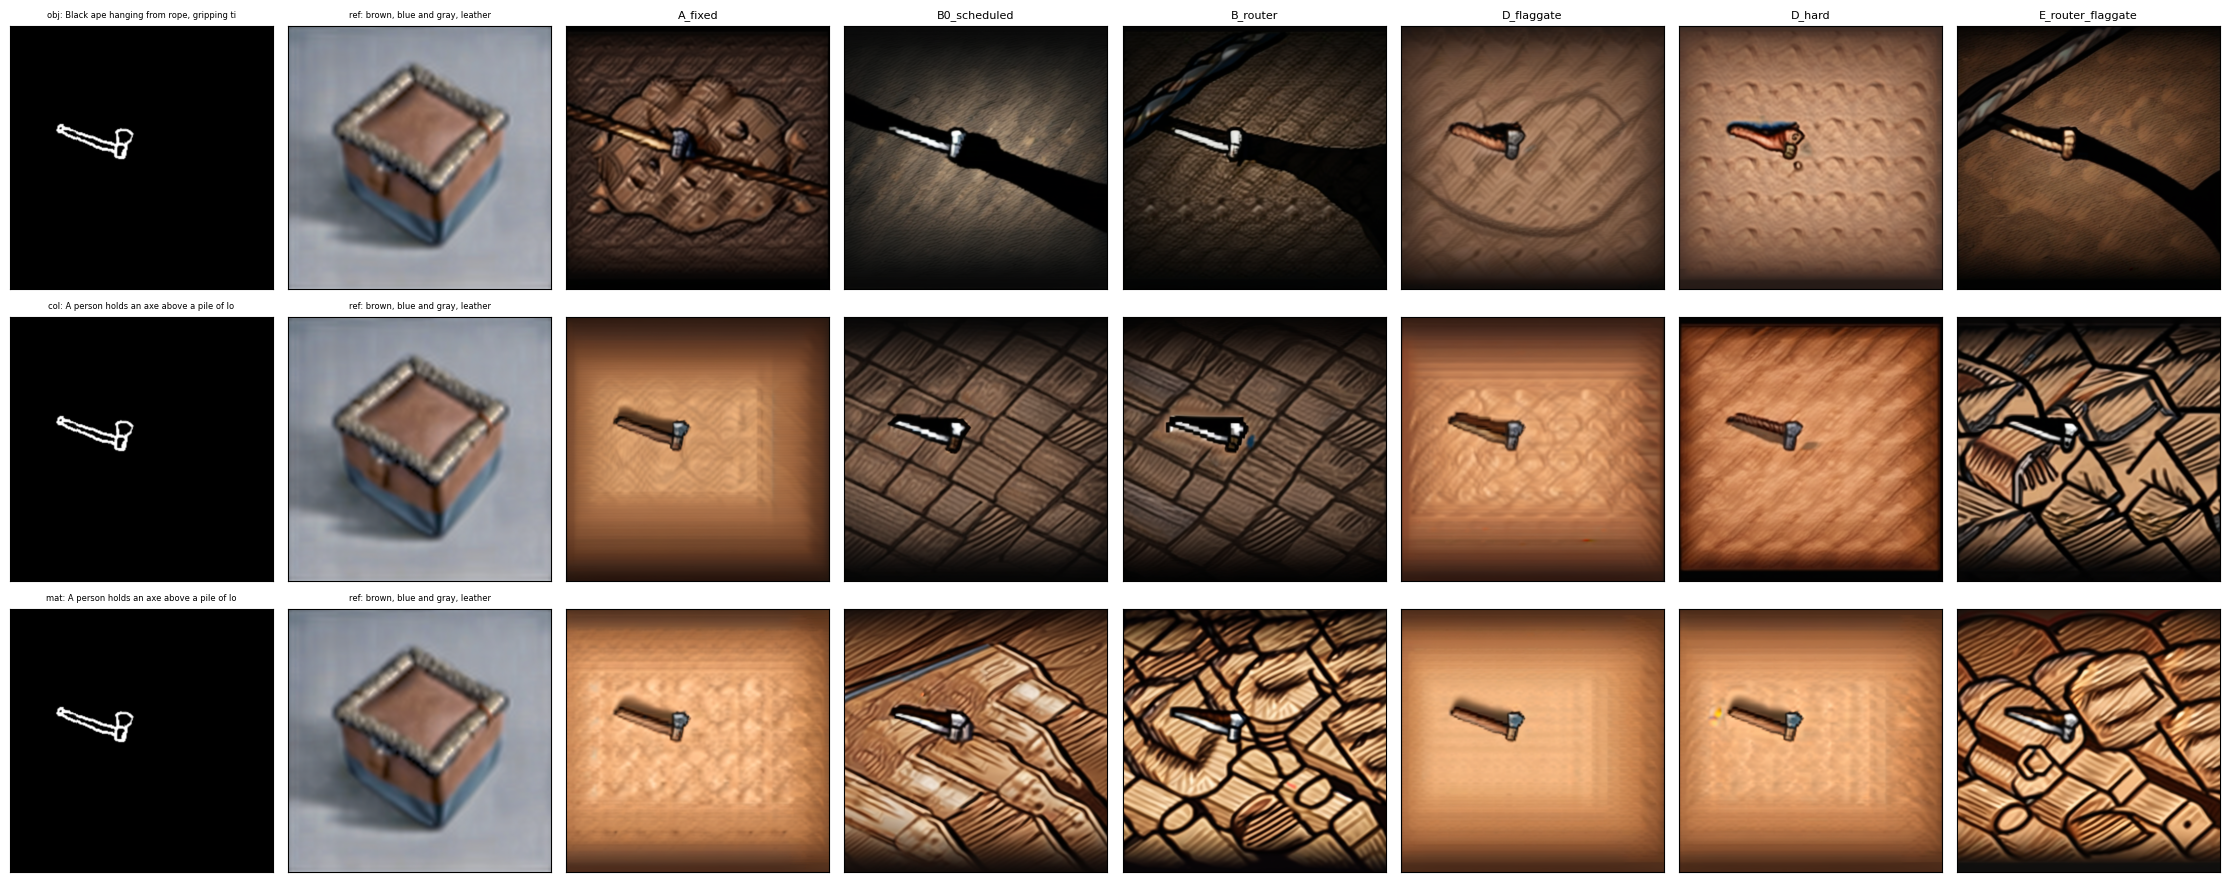

In [5]:
SMOKE = False           # True: colour row only (4 images). False: all 3 rows (resumable, existing images are skipped)
OUT = "/content/pilot_out"
rows = [r for r in ROWS if PF.ER.kind_of(r) == "col"] if SMOKE else ROWS
items, info, S = PF.run_pilot(P, rows, DATA_DIR, OUT, net=net, router=router, kit=KIT)
pd.set_option("display.width", 250)
cols = ["id", "kind", "arm", "pix_diff_vs_A", "edge_iou", "col_hit", "col_share", "col_leak", "mat_hit", "obj_hit", "sem_margin", "id_leak", "dino_ref", "clip_t"]
print(S[[c for c in cols if c in S]].round(3).to_string(index=False))
print(PF.contact_sheet(items, rows, OUT))

In [6]:
import shutil
DEST = f"{DRIVE_ROOT}/sdxl_runs/pilot_flaggate_v1"
shutil.copytree(OUT, DEST, dirs_exist_ok=True)
print("saved to", DEST, sorted(os.listdir(DEST)))

saved to /content/drive/MyDrive/sketchy_dataset_one_sketch/sdxl_runs/pilot_flaggate_v1 ['config.json', 'contact_sheet.png', 'eval', 'scores.csv', 'timings.json']
